# Problem Solving Using Data: Lab 6 - Question 2

## How do we plot coin-flip probabilities with Matplotlib?

In this notebook, we will use Matplotlib to visualize the probabilities associated with flipping a fair coin 10 times.

We will create a weighted sample space, calculate the probability of each possible number of heads, and plot the resulting probability distribution.

## Setup

This notebook is self-contained, so we first import the libraries and define the functions that we need.

In [1]:
import matplotlib.pyplot as plt
import math

We will use the following function to determine whether a value falls inside a specified interval.

In [2]:
def is_in_interval(val, start, end):
    return start <= val <= end

## Creating the Weighted Sample Space

If a fair coin is flipped 10 times, the possible head counts range from 0 heads to 10 heads.

However, each head count does not occur in the same number of coin-flip combinations.

For example, there is only one way to get 10 heads, but there are many ways to get 5 heads.

We use `math.comb()` to calculate how many combinations produce each possible head count.

In [3]:
weighted_sample_space = {
    k: math.comb(10, k)
    for k in range(11)
}

print(weighted_sample_space)

{0: 1, 1: 10, 2: 45, 3: 120, 4: 210, 5: 252, 6: 210, 7: 120, 8: 45, 9: 10, 10: 1}


The dictionary keys represent the number of heads, while the dictionary values represent the number of coin-flip combinations that produce that number of heads.

## Plotting the Weighted Sample Space

We first plot the number of heads against the number of possible coin-flip combinations.

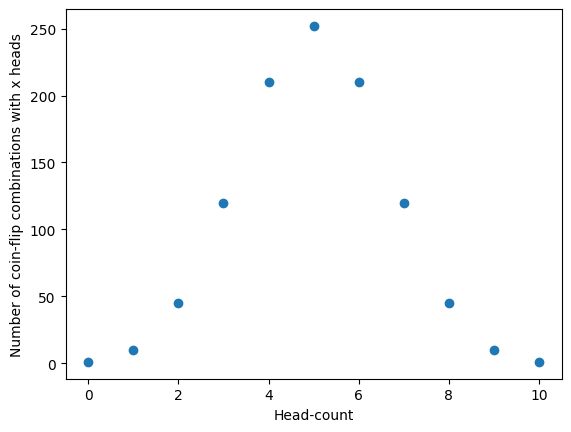

In [4]:
x_10_flips = list(weighted_sample_space.keys())

y_10_flips = [
    weighted_sample_space[key]
    for key in x_10_flips
]

plt.scatter(x_10_flips, y_10_flips)

plt.xlabel('Head-count')
plt.ylabel('Number of coin-flip combinations with x heads')

plt.show()

The graph is symmetric and reaches its highest point at 5 heads.

This shows that outcomes near 5 heads occur in more combinations than outcomes near 0 or 10 heads.

## Converting Combination Counts into Probabilities

To calculate probabilities, we divide each combination count by the total number of possible coin-flip combinations.

In [5]:
sample_space_size = sum(weighted_sample_space.values())

prob_x_10_flips = [
    value / sample_space_size
    for value in y_10_flips
]

print(prob_x_10_flips)

[0.0009765625, 0.009765625, 0.0439453125, 0.1171875, 0.205078125, 0.24609375, 0.205078125, 0.1171875, 0.0439453125, 0.009765625, 0.0009765625]


## Plotting the Probability Distribution

We can now plot each possible head count against its probability.

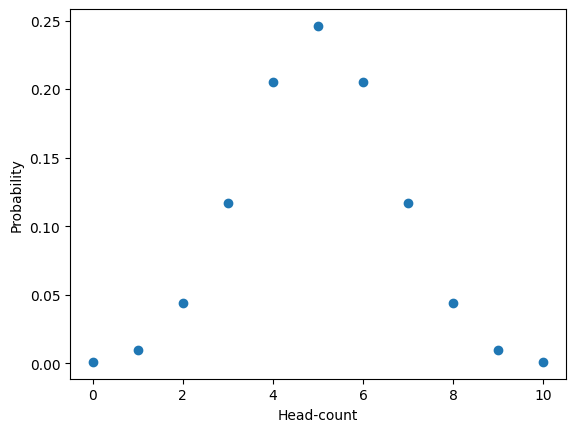

In [6]:
plt.scatter(x_10_flips, prob_x_10_flips)

plt.xlabel('Head-count')
plt.ylabel('Probability')

plt.show()

This graph is a probability distribution.

The x-axis contains every possible number of heads, and the y-axis shows the probability of observing each head count.

The most likely result is approximately 5 heads, while results close to 0 or 10 heads are much less likely.

## Confirming the Total Probability

The probabilities of all possible outcomes should add up to 1.

In [7]:
assert sum(prob_x_10_flips) == 1.0

print("The probabilities add up to:", sum(prob_x_10_flips))

The probabilities add up to: 1.0


## Highlighting 8 or More Heads

The area corresponding to head counts from 8 through 10 represents the probability of observing at least 8 heads.

We can highlight this region using `plt.fill_between()`.

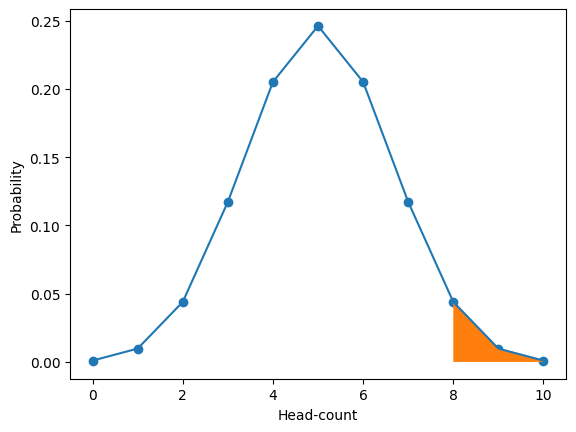

In [8]:
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)

where = [
    is_in_interval(value, 8, 10)
    for value in x_10_flips
]

plt.fill_between(
    x_10_flips,
    prob_x_10_flips,
    where=where
)

plt.xlabel('Head-count')
plt.ylabel('Probability')

plt.show()

The shaded region represents the probability of obtaining 8, 9, or 10 heads from 10 fair coin flips.

These outcomes are considered extreme because they are far away from the expected value of approximately 5 heads.

## Highlighting Both Extreme Ends

An extreme result could also occur in the opposite direction.

For example, 8 or more tails is equivalent to getting 2 or fewer heads.

We can therefore shade both ends of the probability distribution.

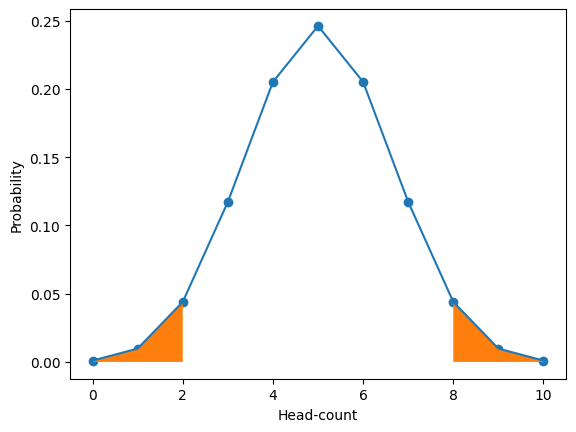

In [9]:
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)

where = [
    not is_in_interval(value, 3, 7)
    for value in x_10_flips
]

plt.fill_between(
    x_10_flips,
    prob_x_10_flips,
    where=where
)

plt.xlabel('Head-count')
plt.ylabel('Probability')

plt.show()

The two shaded regions represent extreme outcomes on both sides of the probability distribution.

The left side represents 2 or fewer heads, while the right side represents 8 or more heads.

Because the fair-coin distribution is symmetric, the extreme regions on the two sides have the same probability.

## Answer to Question 2

To plot coin-flip probabilities with Matplotlib, we first create a weighted sample space that tells us how many coin-flip combinations produce each possible number of heads.

We then divide each combination count by the total number of possible combinations to obtain probabilities.

Finally, we plot:

- head count on the x-axis
- probability on the y-axis

Using `plt.plot()`, `plt.scatter()`, and `plt.fill_between()` allows us to visualize the complete probability distribution and highlight specific probability intervals.

The resulting graph shows that outcomes close to 5 heads are much more likely than extreme outcomes close to 0 or 10 heads.